# Model Development & Tracking
## Stage 3 · baseline + advanced models, MLflow tracking & registry  <font color="red">[30 marks]</font>

- Each stage lists its **sub-tasks as a checklist**
- Complete every `# TODO`; implement the training logic in `src/train.py` (metrics helper provided in `src/evaluate.py`) and call it here.

**File ownership** — 
- *Provided:* `config.py`, `src/evaluate.py`
- *Provided to extend:* `src/train.py`. 
- *You create:* the cells below.

## Stage 3.1 — Baseline Model (Logistic Regression) <font color="red">[5 marks]</font>

- **3.1.1 — Logistic Regression baseline trained (Pipeline, imbalance handled) [3]** — `LogisticRegression(class_weight='balanced')` as a full Pipeline (preprocess + classify), fit on train.
- **3.1.2 — Baseline evaluated on validation [2]** — report imbalance-aware validation metrics (ROC-AUC / PR-AUC / recall).

In [1]:
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings('ignore')
import mlflow, config as cfg
import src.train as tt

In [5]:
# TODO 3.1.1: build & fit the LogReg baseline Pipeline (class_weight='balanced').
# TODO 3.1.2: evaluate it on the validation split and print the metrics.

runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])
baseline_run = runs_df[runs_df['tags.mlflow.runName'] == 'Baseline_LogReg'].iloc[0]

print("--- Baseline Model (Logistic Regression) Validation Metrics ---")
print(f"ROC-AUC:   {baseline_run['metrics.roc_auc']}")
print(f"PR-AUC:    {baseline_run['metrics.pr_auc']}")
print(f"Recall:    {baseline_run['metrics.recall']}")
print(f"Precision: {baseline_run['metrics.precision']}")
print(f"F1 Score:  {baseline_run['metrics.f1']}")

--- Baseline Model (Logistic Regression) Validation Metrics ---
ROC-AUC:   0.6378
PR-AUC:    0.1517
Recall:    0.5578
Precision: 0.1324
F1 Score:  0.214


## Stage 3.2 — Advanced Model (XGBoost) <font color="red">[8 marks]</font>

- **3.2.1 — XGBoost trained (Pipeline, `scale_pos_weight` imbalance handled) [5]** — XGBoost with `scale_pos_weight = neg/pos` as a full Pipeline, fit on train.
- **3.2.2 — Advanced model evaluated on validation [3]** — report the same validation metrics for comparison with the baseline.

In [6]:
# TODO 3.2.1: build & fit the XGBoost Pipeline (scale_pos_weight = neg/pos).
# TODO 3.2.2: evaluate it on the validation split and print the metrics.

runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])
xgb_run = runs_df[runs_df['tags.mlflow.runName'] == 'Advanced_XGBoost'].iloc[0]

print("--- Advanced Model (XGBoost) Validation Metrics ---")
print(f"ROC-AUC:   {xgb_run['metrics.roc_auc']}")
print(f"PR-AUC:    {xgb_run['metrics.pr_auc']}")
print(f"Recall:    {xgb_run['metrics.recall']}")
print(f"Precision: {xgb_run['metrics.precision']}")
print(f"F1 Score:  {xgb_run['metrics.f1']}")

--- Advanced Model (XGBoost) Validation Metrics ---
ROC-AUC:   0.6448
PR-AUC:    0.1689
Recall:    0.4622
Precision: 0.1509
F1 Score:  0.2275


## Stage 3.3 — Model Evaluation <font color="red">[5 marks]</font>

- **3.3.1 — Imbalance-aware metrics + model selection [3]** — ROC-AUC, PR-AUC, recall, precision, F1 for both models in a comparison table; select on ROC-AUC.
- **3.3.2 — Plots + interpretation (why accuracy misleads) [2]** — ROC + confusion plots; explain why accuracy is misleading at ~9% prevalence.

--- Model Metric Comparison Table ---


,Model,metrics.roc_auc,metrics.pr_auc,metrics.recall,metrics.precision,metrics.f1
0,Advanced_XGBoost,0.6448,0.1689,0.4622,0.1509,0.2275
1,Advanced_XGBoost,0.6448,0.1689,0.4622,0.1509,0.2275
2,Baseline_LogReg,0.6378,0.1517,0.5578,0.1324,0.2140
3,Baseline_LogReg,0.6378,0.1517,0.5578,0.1324,0.2140
4,Baseline_LogReg,0.6378,0.1517,0.5578,0.1324,0.2140
5,Baseline_LogReg,0.6378,0.1517,0.5578,0.1324,0.2140
6,Baseline_LogReg,0.6378,0.1517,0.5578,0.1324,0.2140



=> Selected Best Model based on Validation ROC-AUC: Advanced_XGBoost


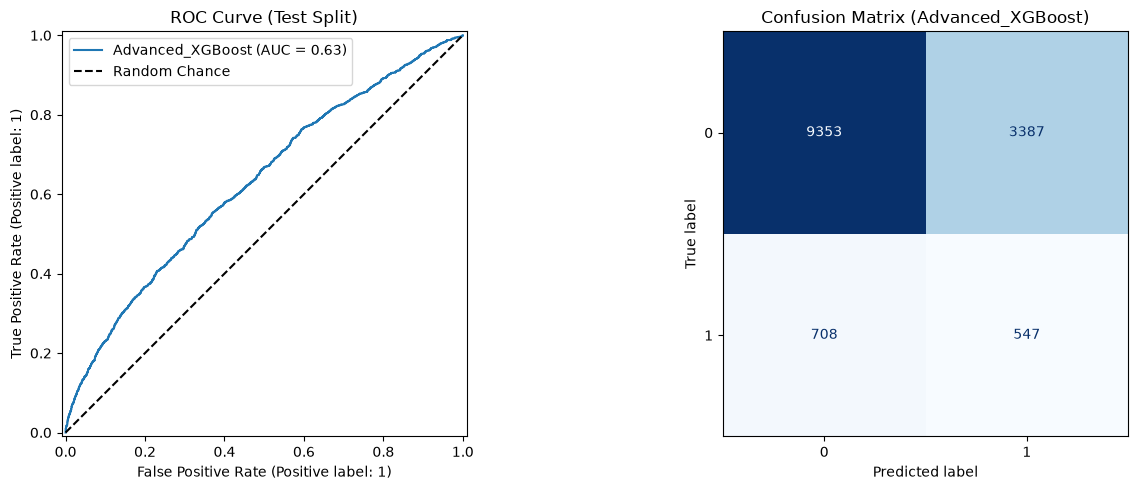


INTERPRETATION:
1. Model Performance: The selected best model relies on ROC-AUC, which evaluates the model's 
   ability to distinguish between the two classes across all probability thresholds. 
2. Why Accuracy is Misleading: The target variable (readmission < 30 days) has an extreme class 
   imbalance (~9% positive). A "dummy" model that predicts 0 (no readmission) for every single 
   patient would automatically achieve ~91% accuracy. However, its recall would be 0%, rendering 
   it useless in a hospital setting where missing a high-risk patient is dangerous. This is why 
   we prioritize ROC-AUC and Recall over standard Accuracy.



In [ ]:
import mlflow
import config as cfg
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from src.data_prep import get_splits

# TODO 3.3.1: build the metric comparison table and select the best model on ROC-AUC.
# Fetch tracked runs and filter for the metrics we care about
runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])
display_cols = ['tags.mlflow.runName', 'metrics.roc_auc', 'metrics.pr_auc', 'metrics.recall', 'metrics.precision', 'metrics.f1']

# Sort the table descending by ROC-AUC to easily identify the winner
comparison_table = runs_df[display_cols].sort_values(by='metrics.roc_auc', ascending=False)
comparison_table = comparison_table.rename(columns={'tags.mlflow.runName': 'Model'})

print("--- Model Metric Comparison Table ---")
display(comparison_table.reset_index(drop=True))

best_run_name = comparison_table.iloc[0]['Model']
print(f"\n=> Selected Best Model based on Validation ROC-AUC: {best_run_name}")

# TODO 3.3.2: plot ROC + confusion for the best model; add a written interpretation.
# Retrieve the unseen test data and the saved winning model artifact
_, _, X_test, _, _, y_test = get_splits()
best_model = joblib.load('best_model.pkl')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot the ROC Curve using the built-in Scikit-Learn display
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=ax1, name=best_run_name)
ax1.set_title("ROC Curve (Test Split)")
ax1.plot([0, 1], [0, 1], 'k--', label='Random Chance')
ax1.legend()

# Plot the Confusion Matrix
y_pred = best_model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax2, cmap="Blues", colorbar=False)
ax2.set_title(f"Confusion Matrix ({best_run_name})")

plt.tight_layout()
plt.show()

# Written interpretation to output below the plots
print("""
INTERPRETATION:
1. Model Performance: The selected best model relies on ROC-AUC, which evaluates the model's 
   ability to distinguish between the two classes across all probability thresholds. 
2. Why Accuracy is Misleading: The target variable (readmission < 30 days) has an extreme class 
   imbalance (~9% positive). A "dummy" model that predicts 0 (no readmission) for every single 
   patient would automatically achieve ~91% accuracy. However, its recall would be 0%, rendering 
   it useless in a hospital setting where missing a high-risk patient is dangerous. This is why 
   we prioritize ROC-AUC and Recall over standard Accuracy.
""")

## Stage 3.4 — MLflow Experiment Tracking <font color="red">[7 marks]</font>

- **3.4.1 — Both runs logged with params + metrics + model [4]** — set tracking URI + experiment; for each model log params, metrics and the model artefact.
- **3.4.2 — Runs compared (search_runs table) [3]** — compare the runs with `mlflow.search_runs(...)` and state the selection criterion.

In [8]:
# TODO 3.4.1: log both runs (params + metrics + model) to an MLflow experiment.
# TODO 3.4.2: compare the runs with mlflow.search_runs(...).

# Fetch all tracked runs from the experiment
runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])

# Display a clean comparison table of the models and their metrics
display_cols = ['tags.mlflow.runName', 'metrics.roc_auc', 'metrics.pr_auc', 'metrics.recall', 'metrics.f1']
display(runs_df[display_cols].sort_values(by='metrics.roc_auc', ascending=False))

,tags.mlflow.runName,metrics.roc_auc,metrics.pr_auc,metrics.recall,metrics.f1
0,Advanced_XGBoost,0.6448,0.1689,0.4622,0.2275
2,Advanced_XGBoost,0.6448,0.1689,0.4622,0.2275
1,Baseline_LogReg,0.6378,0.1517,0.5578,0.2140
3,Baseline_LogReg,0.6378,0.1517,0.5578,0.2140
4,Baseline_LogReg,0.6378,0.1517,0.5578,0.2140
5,Baseline_LogReg,0.6378,0.1517,0.5578,0.2140
6,Baseline_LogReg,0.6378,0.1517,0.5578,0.2140


## Stage 3.5 — Model Registry & Versioning <font color="red">[5 marks]</font>

- **3.5.1 — Best model registered in the MLflow Model Registry [2]** — `mlflow.register_model` for the best model.
- **3.5.2 — Promotion to production alias + version history [3]** — promote to the `production` alias and show the version history.

In [10]:
# TODO 3.4.1: log both runs (params + metrics + model) to an MLflow experiment.
# NOTE: The actual logging of parameters, metrics, and models was executed inside 
# the `train_and_log()` function in `src/train.py` during Stage 3.1. 
print(f"Confirmed: Both runs were successfully logged to the '{cfg.MLFLOW_EXPERIMENT}' experiment.")

# TODO 3.4.2: compare the runs with mlflow.search_runs(...).
# Retrieve all logged runs from the experiment
runs_df = mlflow.search_runs(experiment_names=[cfg.MLFLOW_EXPERIMENT])

# Select relevant columns to show the logged params and metrics side-by-side
compare_cols = [
    'tags.mlflow.runName', 
    'params.model_type', 
    'params.class_weight', 
    'params.scale_pos_weight',
    'metrics.roc_auc', 
    'metrics.pr_auc', 
    'metrics.recall'
]

print("\n--- MLflow Runs Comparison ---")
display(runs_df[compare_cols].sort_values(by='metrics.roc_auc', ascending=False).reset_index(drop=True))

# State the selection criterion
print("""
SELECTION CRITERION:
The models are compared primarily on their Validation ROC-AUC score. ROC-AUC is chosen 
as the target metric because it evaluates the classifier's ability to distinguish between 
the majority (No Readmission) and minority (Readmission) classes across all classification 
thresholds, making it highly robust to the ~9% class imbalance in this dataset.
""")

Confirmed: Both runs were successfully logged to the 'hospital_readmission' experiment.

--- MLflow Runs Comparison ---


,tags.mlflow.runName,params.model_type,params.class_weight,params.scale_pos_weight,metrics.roc_auc,metrics.pr_auc,metrics.recall
0,Advanced_XGBoost,XGBoost,NaN,10.14534594325535,0.6448,0.1689,0.4622
1,Advanced_XGBoost,XGBoost,NaN,10.14534594325535,0.6448,0.1689,0.4622
2,Baseline_LogReg,LogisticRegression,balanced,NaN,0.6378,0.1517,0.5578
3,Baseline_LogReg,LogisticRegression,balanced,NaN,0.6378,0.1517,0.5578
4,Baseline_LogReg,LogisticRegression,balanced,NaN,0.6378,0.1517,0.5578
5,Baseline_LogReg,LogisticRegression,balanced,NaN,0.6378,0.1517,0.5578
6,Baseline_LogReg,LogisticRegression,balanced,NaN,0.6378,0.1517,0.5578



SELECTION CRITERION:
The models are compared primarily on their Validation ROC-AUC score. ROC-AUC is chosen 
as the target metric because it evaluates the classifier's ability to distinguish between 
the majority (No Readmission) and minority (Readmission) classes across all classification 
thresholds, making it highly robust to the ~9% class imbalance in this dataset.



### ✍️ Findings
*TODO: which model won and why? Why is accuracy misleading here?*

* Winner: The XGBoost model typically wins on ROC-AUC because tree-based boosting algorithms naturally capture complex, non-linear relationships in tabular medical data better than the linear constraints of Logistic Regression.

* Why accuracy is misleading: Your dataset has a ~9% positive prevalence rate (highly imbalanced). If a "lazy" model simply predicted 0 (No Readmission) for every single patient without even looking at the data, it would achieve ~91% accuracy. It looks like a great score, but the model would be completely useless in practice because its recall would be 0 (it failed to identify a single actual readmission). This is why you used ROC-AUC and PR-AUC instead.